# Forecasting Daily AQI in Mumbai: Applied Time Series Analysis

Walkthrough of the professor's 11-step workflow. Light steps are computed live here with the project's `src/` modules;
the order search and rolling-origin evaluation (a few minutes) are loaded from `artifacts/mumbai.json`, written by `run_pipeline.py` with the same code.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from src import data as dl, analysis as an
from src.config import TRAIN_END, VAL_END
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)
CITY, START = "Mumbai", "2019-01-01"
A = json.loads((ROOT / "artifacts" / "mumbai.json").read_text())

## 1. Data collection

In [2]:
raw = dl.load_raw()
cf = dl.city_frame(raw, CITY)
pd.Series(dl.data_card(raw, cf, CITY))

rows_all_cities                                                    471015
n_cities                                                              297
columns                 [date, city, no_stations, aqi_category, aqi, p...
date_min                                                       2015-05-01
date_max                                                       2025-12-31
city                                                               Mumbai
city_first                                                     2015-08-20
city_last                                                      2025-12-31
city_calendar_days                                                   3787
city_observed_days                                                   3614
duplicates_city_date                                                    0
zero_aqi_values                                                         0
frequency               daily (one bulletin per day, city AQI = averag...
units                              CPC

In [3]:
raw.head()

,date,city,no_stations,aqi_category,aqi,prominent_pollutant
0,2020-11-09,Agartala,1,Satisfactory,67,PM2.5
1,2020-11-10,Agartala,1,Satisfactory,73,PM2.5
2,2020-11-11,Agartala,1,Satisfactory,90,PM2.5
3,2020-11-12,Agartala,1,Satisfactory,75,PM2.5
4,2020-11-13,Agartala,1,Satisfactory,66,PM2.5


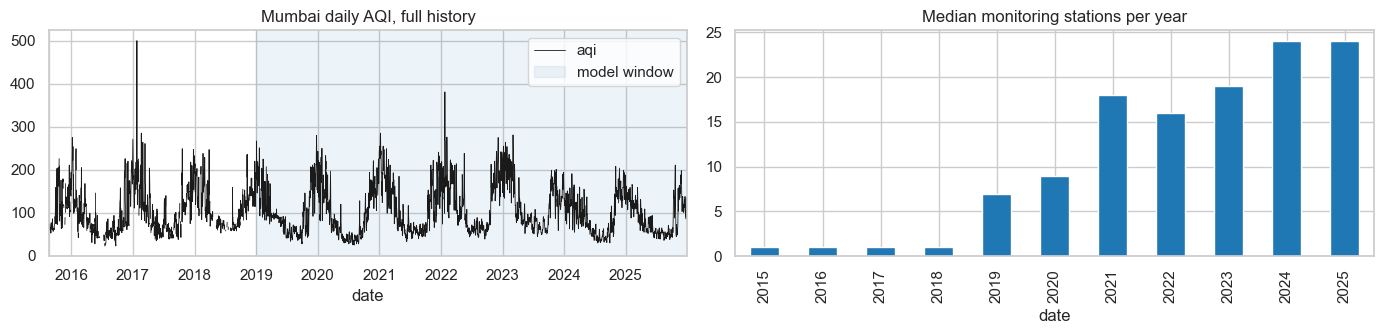

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
cf["aqi"].plot(ax=ax[0], lw=0.6, color="k", title="Mumbai daily AQI, full history")
ax[0].axvspan(pd.Timestamp(START), cf.index[-1], color="tab:blue", alpha=0.08, label="model window")
ax[0].legend()
cf["no_stations"].groupby(cf.index.year).median().plot.bar(ax=ax[1], color="tab:blue", title="Median monitoring stations per year")
plt.tight_layout()

Mumbai's city AQI came from one station until 2018 and from 7 to 24 afterwards, so the modelling window starts on 2019-01-01.

## 3. Missing values

In [5]:
pd.Series(dl.missingness_summary(cf, START)).drop(["missing_by_weekday"])

full_missing_days                                                       173
full_missing_pct                                                       4.57
full_longest_gap                                                         19
full_gap_length_counts    {1: 63, 2: 8, 3: 3, 4: 1, 5: 4, 6: 2, 9: 2, 12...
window_missing_days                                                       5
window_missing_pct                                                    0.196
window_longest_gap                                                        2
window_missing_dates      [2019-02-28, 2019-03-01, 2019-04-02, 2023-09-2...
missing_by_year           {2015: 16, 2016: 52, 2017: 18, 2018: 82, 2019:...
dtype: object

In [6]:
pd.DataFrame(dl.compare_imputation(cf["aqi"][START:VAL_END]))

,method,mae,n_blocks
0,time,14.07,299
1,ffill,19.25,299
2,weekly,29.08,299


In [7]:
s = dl.impute(cf["aqi"][START:], "time")   # gaps <= 3 days only, on the log scale
y = np.log(s)
print("remaining NaN:", s.isna().sum(), "| zero AQI values:", (s == 0).sum())

remaining NaN: 0 | zero AQI values: 0


## 2. Exploratory data analysis

In [8]:
pd.Series(an.describe(s))

count              2557.000
mean                104.240
std                  54.870
min                  25.000
5%                   39.000
25%                  59.000
50%                  89.000
75%                 141.000
95%                 209.000
max                 381.000
skewness              0.832
excess_kurtosis       0.007
log_skewness          0.012
dtype: float64

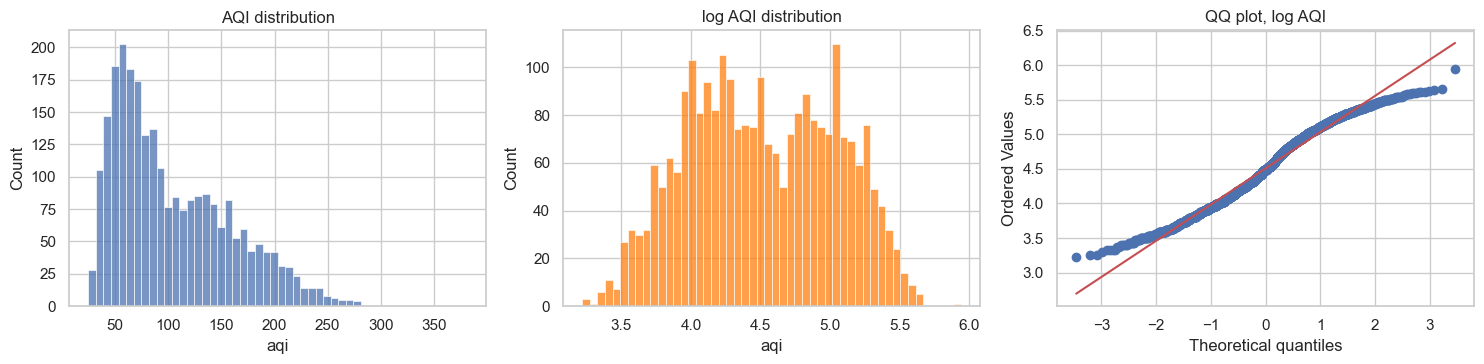

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.histplot(s, bins=50, ax=ax[0]); ax[0].set_title("AQI distribution")
sns.histplot(y, bins=50, ax=ax[1], color="tab:orange"); ax[1].set_title("log AQI distribution")
stats.probplot(y, dist="norm", plot=ax[2]); ax[2].set_title("QQ plot, log AQI")
plt.tight_layout()

Kruskal-Wallis p (month): 0.0 | (weekday): 0.989


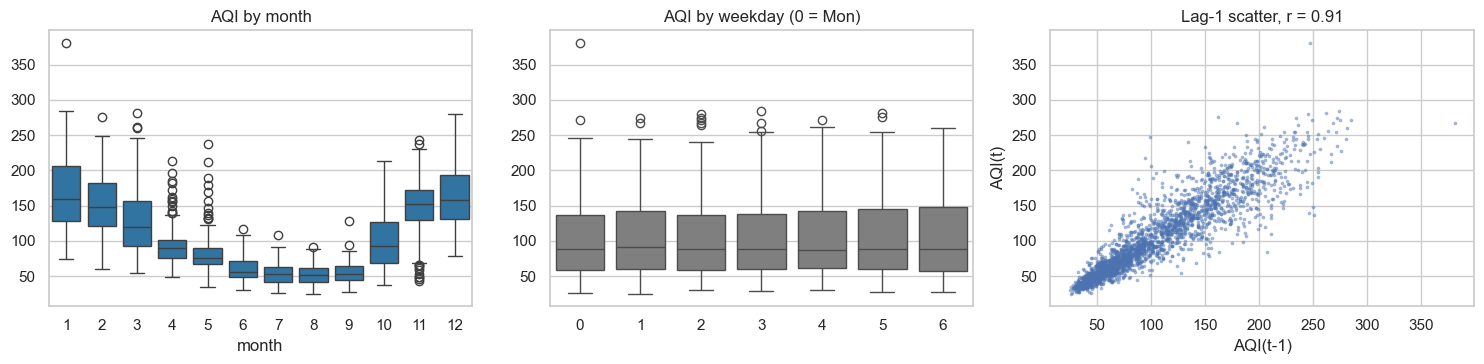

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.boxplot(x=s.index.month, y=s.values, ax=ax[0], color="tab:blue"); ax[0].set(title="AQI by month", xlabel="month")
sns.boxplot(x=s.index.dayofweek, y=s.values, ax=ax[1], color="tab:gray"); ax[1].set(title="AQI by weekday (0 = Mon)", xlabel="")
ax[2].scatter(s.shift(1), s, s=3, alpha=0.4); ax[2].set(title=f"Lag-1 scatter, r = {s.autocorr(1):.2f}", xlabel="AQI(t-1)", ylabel="AQI(t)")
plt.tight_layout()
sp = an.seasonal_profiles(s)
print("Kruskal-Wallis p (month):", sp["kruskal_month_p"], "| (weekday):", round(sp["kruskal_weekday_p"], 3))

,aqi,robust_z
date,,
2021-04-27,185.0,8.20
2024-02-02,63.0,-7.88
2024-02-21,60.0,-5.68
2024-02-22,64.0,-5.11
2022-10-25,213.0,4.91
2021-04-26,129.0,4.72
2023-11-27,59.0,-4.32
2021-04-28,125.0,4.30
2022-05-19,238.0,4.23


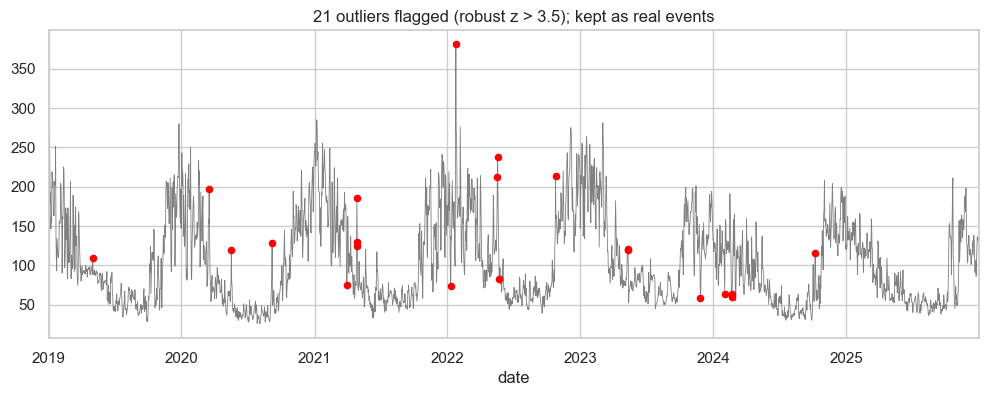

In [11]:
out = an.outliers(s)
ax = s.plot(lw=0.6, color="gray", title=f"{len(out)} outliers flagged (robust z > 3.5); kept as real events")
ax.scatter(out.index, out["aqi"], color="red", s=20, zorder=3)
out.sort_values("robust_z", key=abs, ascending=False).head(10)

## 4. Stationarity

Text(0.5, 1.0, 'Rolling statistics (training)')

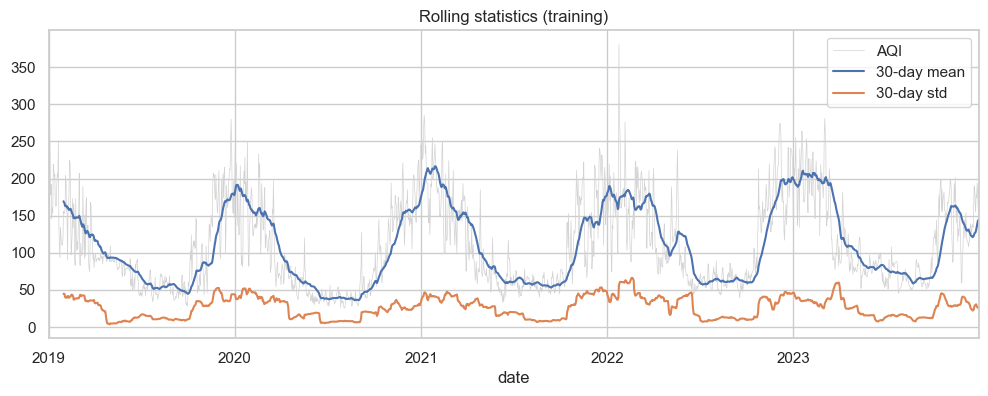

In [12]:
ytr, str_ = y[:TRAIN_END], s[:TRAIN_END]
r = an.rolling_stats(str_, 30)
ax = str_.plot(lw=0.5, color="lightgray", label="AQI"); r["mean"].plot(ax=ax, label="30-day mean"); r["std"].plot(ax=ax, label="30-day std"); ax.legend(); ax.set_title("Rolling statistics (training)")

In [13]:
variants = {"AQI": str_, "log AQI": ytr, "diff log AQI": ytr.diff(), "seasonal diff (7)": ytr.diff(7)}
rows = an.stationarity_suite(variants)
pd.DataFrame([{"series": r["series"], "ADF stat": r["adf"]["statistic"], "ADF p": round(r["adf"]["p_value"], 4),
               "KPSS stat": r["kpss"]["statistic"], "KPSS p": r["kpss"]["p_value"], "verdict": r["verdict"]} for r in rows])

,series,ADF stat,ADF p,KPSS stat,KPSS p,verdict
0,AQI,-3.6369,0.0051,0.2180,0.1,stationary
1,log AQI,-3.4573,0.0092,0.2827,0.1,stationary
2,diff log AQI,-20.2727,0.0000,0.0601,0.1,stationary
3,seasonal diff (7),-10.1561,0.0000,0.0668,0.1,stationary


ADF H0: unit root. KPSS H0: stationarity. Both agree that log AQI is stationary around its seasonal level (KPSS p is capped at 0.10 by statsmodels).

## 5. Transformations

In [14]:
print("Box-Cox lambda:", round(an.boxcox_lambda(str_), 3), "(0 = log)")
print(an.variance_by_level(str_))

Box-Cox lambda: 0.03 (0 = log)
{'corr_mean_std_raw': 0.813, 'corr_mean_std_log': 0.29}


Lambda close to 0 and the drop in mean-variance correlation justify modelling log AQI. Forecasts are back-transformed with exp() (median) and capped at 500.

## 6. Seasonality and decomposition

{'trend_strength': np.float64(0.183),
 'weekly_strength': np.float64(0.045),
 'annual_strength': np.float64(0.777)}

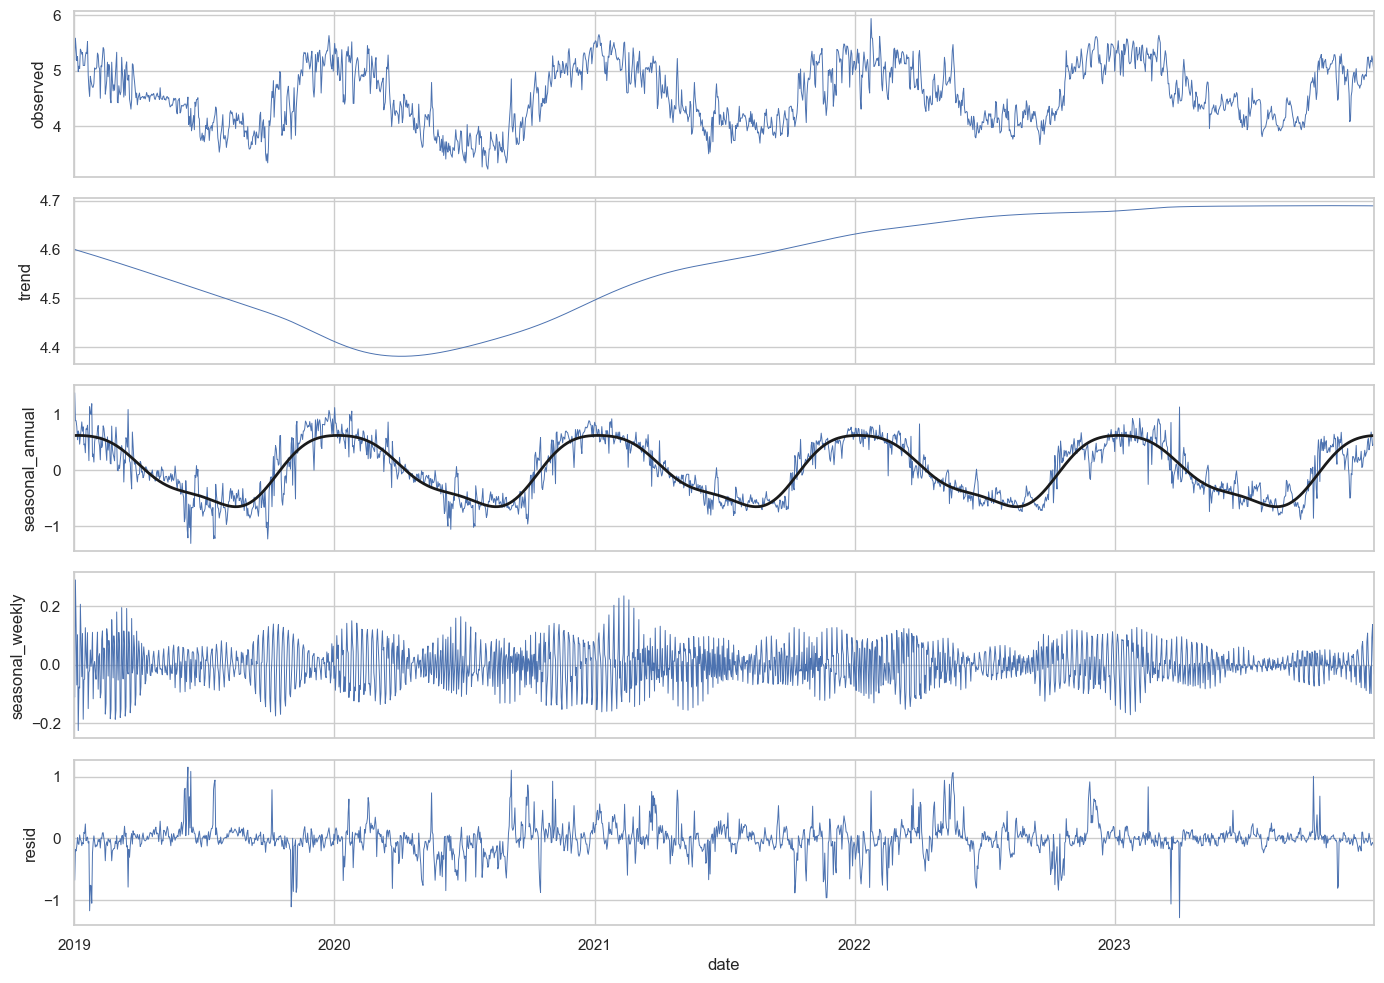

In [15]:
dec = an.mstl_decompose(ytr)
fig, ax = plt.subplots(5, 1, figsize=(14, 10), sharex=True)
for a, c in zip(ax, ["observed", "trend", "seasonal_annual", "seasonal_weekly", "resid"]):
    dec[c].plot(ax=a, lw=0.7); a.set_ylabel(c)
dec["annual_fourier"].plot(ax=ax[2], color="k", lw=2)
plt.tight_layout()
an.seasonal_strength(dec)

## 7. ACF and PACF

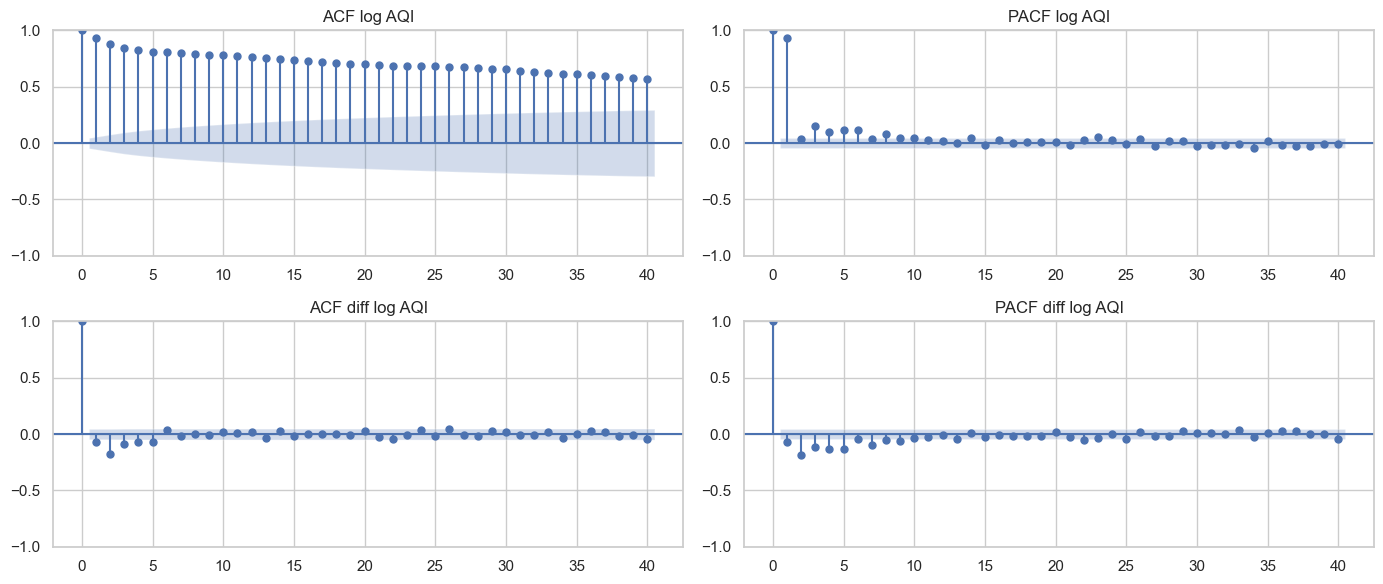

In [16]:
fig, ax = plt.subplots(2, 2, figsize=(14, 6))
plot_acf(ytr, lags=40, ax=ax[0, 0], title="ACF log AQI"); plot_pacf(ytr, lags=40, ax=ax[0, 1], method="ywm", title="PACF log AQI")
plot_acf(ytr.diff().dropna(), lags=40, ax=ax[1, 0], title="ACF diff log AQI"); plot_pacf(ytr.diff().dropna(), lags=40, ax=ax[1, 1], method="ywm", title="PACF diff log AQI")
plt.tight_layout()

Slow ACF decay with a PACF cut-off suggests AR structure on levels; the differenced series shows a negative lag-1 ACF, suggesting an MA term with d = 1.

## 9 and 10. Lag selection, AIC and BIC (from the pipeline)

In [17]:
cand = pd.DataFrame(A["candidates"])
pd.DataFrame({f: {"selected": v["label"]} for f, v in A["selected_orders"].items()}).T

,selected
AR,"AR (10,0,0)"
MA,"MA (0,0,10)"
ARMA,"ARMA (3,0,3)"
ARIMA,"ARIMA (2,1,3)"
SARIMA,"SARIMA (3,0,3)(0,0,1)[7]"
SARIMAX-Fourier,"SARIMAX-Fourier (3,0,0) + Fourier K=2"


,family,label,d_total,k_params,loglik,aic,bic
64,SARIMAX-Fourier,"SARIMAX-Fourier (3,0,0) + Fourier K=2",0,9,507.42,-996.83,-947.24
69,SARIMAX-Fourier,"SARIMAX-Fourier (3,0,0) + Fourier K=3",0,11,508.75,-995.51,-934.90
74,SARIMAX-Fourier,"SARIMAX-Fourier (3,0,0) + Fourier K=4",0,13,510.16,-994.32,-922.69
59,SARIMAX-Fourier,"SARIMAX-Fourier (3,0,0) + Fourier K=1",0,7,503.14,-992.27,-953.70
63,SARIMAX-Fourier,"SARIMAX-Fourier (2,0,1) + Fourier K=2",0,9,502.05,-986.09,-936.51
68,SARIMAX-Fourier,"SARIMAX-Fourier (2,0,1) + Fourier K=3",0,11,503.61,-985.23,-924.62
73,SARIMAX-Fourier,"SARIMAX-Fourier (2,0,1) + Fourier K=4",0,13,505.24,-984.48,-912.86
62,SARIMAX-Fourier,"SARIMAX-Fourier (1,0,1) + Fourier K=2",0,8,499.82,-983.63,-939.55
61,SARIMAX-Fourier,"SARIMAX-Fourier (2,0,0) + Fourier K=2",0,8,499.42,-982.84,-938.76
67,SARIMAX-Fourier,"SARIMAX-Fourier (1,0,1) + Fourier K=3",0,10,501.41,-982.81,-927.72


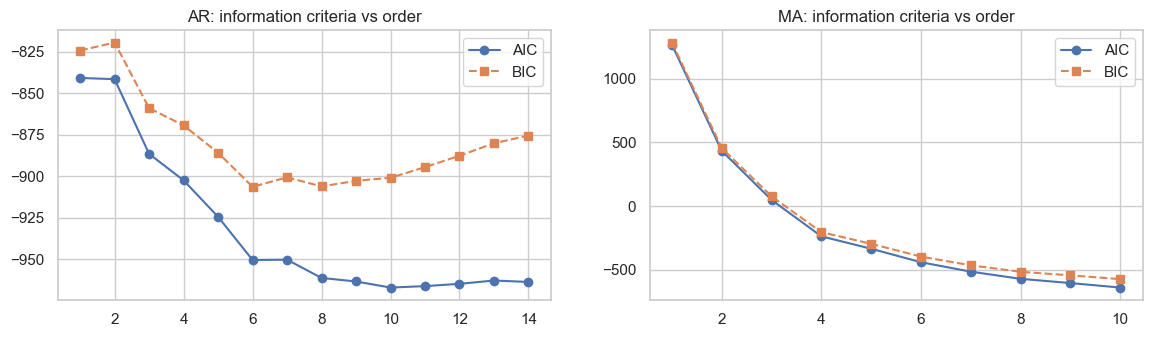

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
for a, fam, i in [(ax[0], "AR", 0), (ax[1], "MA", 2)]:
    c = cand[cand.family == fam].assign(o=lambda d: d.order.str[i]).sort_values("o")
    a.plot(c.o, c.aic, "o-", label="AIC"); a.plot(c.o, c.bic, "s--", label="BIC"); a.set_title(f"{fam}: information criteria vs order"); a.legend()
cand.sort_values(["d_total", "aic"])[["family", "label", "d_total", "k_params", "loglik", "aic", "bic"]].head(15)

## 8. Model comparison on the 2025 test year (rolling origin, 1 / 3 / 7 days ahead)

In [19]:
tm = pd.DataFrame(A["test_metrics"])
print("Selected on 2024 validation:", A["selected_model"])
tm.pivot(index="model", columns="h", values="RMSE").sort_values(1).round(1)

Selected on 2024 validation: AR (10,0,0)


h,1,3,7
model,,,
"SARIMAX-Fourier (3,0,0) + Fourier K=2",14.8,21.9,26.6
"AR (10,0,0)",15.2,22.7,27.6
"ARMA (3,0,3)",15.2,22.7,27.4
"SARIMA (3,0,3)(0,0,1)[7]",15.2,22.7,27.4
"ARIMA (2,1,3)",15.3,23.0,28.0
Holt-Winters ETS,15.4,24.1,29.7
Naive,15.5,24.1,29.7
"MA (0,0,10)",15.6,25.2,34.2
Seasonal naive (7d),29.8,29.7,29.7


In [20]:
tm[tm.h == 1].sort_values("RMSE")[["model", "MAE", "RMSE", "MAPE", "sMAPE", "MASE", "cov80", "cov95", "category_acc"]]

,model,MAE,RMSE,MAPE,sMAPE,MASE,cov80,cov95,category_acc
24,"SARIMAX-Fourier (3,0,0) + Fourier K=2",10.40,14.80,12.08,11.61,0.651,87.7,97.3,83.0
9,"AR (10,0,0)",10.31,15.15,11.84,11.61,0.646,88.2,97.3,83.6
15,"ARMA (3,0,3)",10.42,15.17,11.89,11.68,0.652,87.4,97.5,83.8
21,"SARIMA (3,0,3)(0,0,1)[7]",10.42,15.18,11.89,11.68,0.652,87.4,97.5,83.8
18,"ARIMA (2,1,3)",10.47,15.27,11.88,11.73,0.656,87.7,97.5,83.0
6,Holt-Winters ETS,10.61,15.44,12.09,11.90,0.664,89.6,97.5,83.0
0,Naive,10.66,15.53,12.15,11.96,0.667,90.4,97.8,82.5
12,"MA (0,0,10)",11.16,15.64,13.21,12.76,0.699,89.6,98.4,81.4
3,Seasonal naive (7d),19.95,29.85,23.46,21.89,1.249,87.9,95.9,71.8


In [21]:
dm = pd.DataFrame(A["dm_tests"])
dm["p_one_sided_better"] = np.where(dm.stat < 0, dm.p_value / 2, 1 - dm.p_value / 2)
dm.pivot(index="model", columns="h", values="p_one_sided_better").round(4)

h,1,3,7
model,,,
"AR (10,0,0)",0.2347,0.1513,0.0853
"ARIMA (2,1,3)",0.3405,0.2365,0.2207
"ARMA (3,0,3)",0.2842,0.1780,0.1425
Holt-Winters ETS,0.1107,0.5298,0.9930
"MA (0,0,10)",0.5990,0.7698,0.9049
"SARIMA (3,0,3)(0,0,1)[7]",0.2884,0.1809,0.1471
"SARIMAX-Fourier (3,0,0) + Fourier K=2",0.1065,0.0696,0.1398
Seasonal naive (7d),1.0000,0.9449,NaN


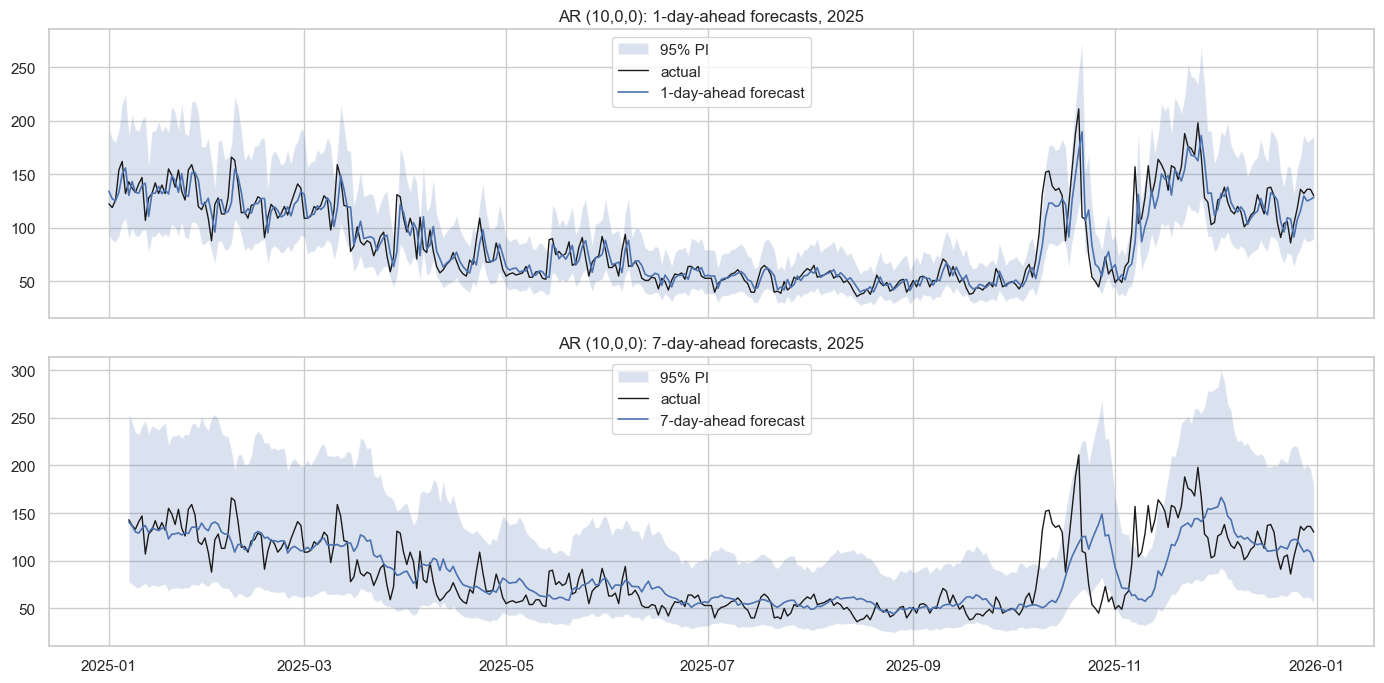

In [22]:
sel = A["selected_model"]
fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for a, h in zip(ax, ["1", "7"]):
    p = pd.DataFrame(A["test_paths"][sel][h]); p["date"] = pd.to_datetime(p.date)
    a.fill_between(p.date, p.lo95, p.hi95, alpha=0.2, label="95% PI"); a.plot(p.date, p.actual, "k", lw=1, label="actual"); a.plot(p.date, p.forecast, lw=1.2, label=f"{h}-day-ahead forecast")
    a.set_title(f"{sel}: {h}-day-ahead forecasts, 2025"); a.legend()
plt.tight_layout()

## 11. Residual diagnostics (selected model)

(   lag   stat   p_value
 0    7   0.85  0.357839
 1   14   7.51  0.482703
 2   28  16.30  0.800979,
 {'stat': 142.16,
  'p_value': 1.3475669738602209e-31,
  'skew': 0.068,
  'excess_kurtosis': 1.249})

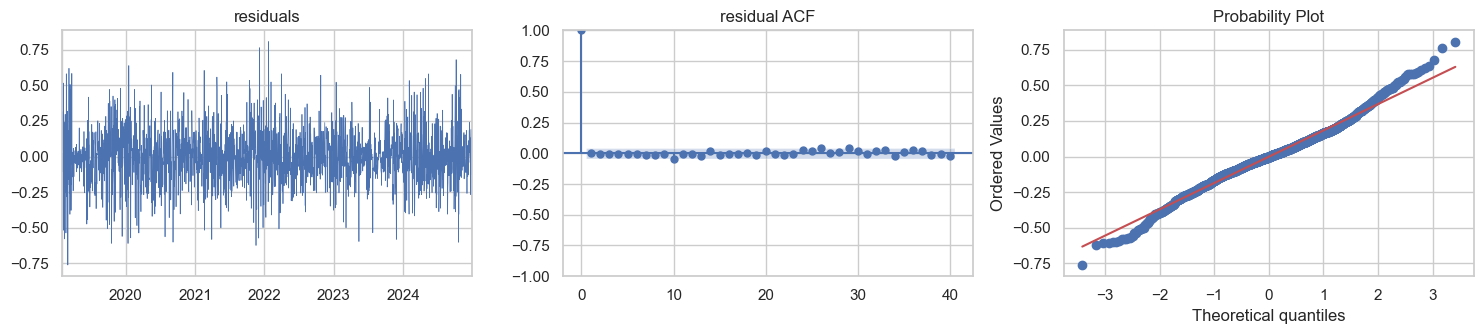

In [23]:
g = A["diagnostics"][sel]
r = pd.Series(g["series"]["value"], index=pd.to_datetime(g["series"]["date"]))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
r.plot(ax=ax[0], lw=0.5, title="residuals"); plot_acf(r, lags=40, ax=ax[1], title="residual ACF"); stats.probplot(r, plot=ax[2])
plt.tight_layout()
pd.DataFrame(g["ljung_box"]), g["jarque_bera"]

## Deployment

`python -m uvicorn app.server:app --port 8000` serves the dashboard at http://localhost:8000. It uses the same trained parameters (`production` in the artifact) to forecast live, and exports CSV.

## Limitations

Univariate; heavy-tailed residuals; station network changes; evaluated up to 7 days ahead. Forecasts are study estimates, not official CPCB forecasts.